In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.2 USBメモリのデバイス名の探し方 (*Finding USB Device Names*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.2_Finding_USB_Device_Names.ipynb)

名著『**ゼロからのOS自作入門**』（内田公太 著、マイナビ出版）第1章 1.2 節の解説ノートブックです。前節（1.1節）で作成した最小 UEFI アプリケーション（`BOOTX64.EFI`）を実機 PC で起動するために不可欠な、**Linux におけるブロックデバイス管理、メジャー/マイナー番号のビット構造、USB エニュメレーションシーケンス、FAT32 ファイルシステム配置、およびホストディスク誤破壊防止プロトコル** を完全自己完結で解明します。

> [!IMPORTANT]
> **本節の学習ゴール**:
> 1. **「すべてはファイルである」UNIX 哲学の具現化**: キャラクタデバイスとブロックデバイスの違い、および Linux カーネルの `dev_t`（メジャー番号/マイナー番号）のビットレイアウトとドライバ紐付けの仕組みを理解する。
> 2. **ストレージ命名規則の変遷**: `/dev/hdX`（IDE）、`/dev/sdX`（SCSI/SATA/USB）、`/dev/nvmeXnYpZ`（NVMe）の階層構造と命名規則の完全な論理を把握する。
> 3. **USB 接続からデバイスノード生成までの完全シーケンス**: 電気的検知 → xHCI → usbcore → usb-storage / uas → SCSI サブシステム → sysfs (`/sys/block/`) → uevent (Netlink) → udev による `/dev/sdX` 動的生成フローを追跡する。
> 4. **UEFI ブートメディアの仕様**: なぜ UEFI ファームウェアは FAT32 (または FAT16/12) を要求するのか、および `/EFI/BOOT/BOOTX64.EFI` のディレクトリ階層とパーティションテーブル（GPT/MBR）の構造を数理・ビットレベルで俯瞰する。
> 5. **誤破壊防止（Accidental Data Loss Prevention）プロトコル**: ホストのルートストレージ（`/dev/sda` や `/dev/nvme0n1`）を誤って破壊しないための差分特定プロトコルを C++20 および Python で実装・検証する。

---

## 1. なぜ「デバイス名の探し方」を学ぶのか？ — 実機ブートの壁と壊滅的リスク

### 1.1 前節（1.1節）の成果と立ちはだかる課題
前節（1.1節）において、私たちは PE32+ (Portable Executable 64-bit) 規格の仕様書を解読し、わずか 1536 バイトのバイナリ `BOOTX64.EFI` を合成・解析しました。このバイナリは x86-64 の CPU 命令列を含んでおり、UEFI のエントリポイントから呼び出されれば直ちに画面に `Hello, world!` を出力する能力を備えています。

しかし、**ファイルが手元の作業ディレクトリ（ディスク上）にあるだけでは、PC はそれを実行できません**。OS 自作の醍醐味である「実機 PC でのベアメタル起動」を果たすには、この実行可能バイナリを物理的なブートメディア、すなわち **USB フラッシュドライブ (*USB Flash Drive*)** に書き込む必要があります。

### 1.2 Windows と Linux の決定的な違い
一般的なデスクトップ OS である Windows では、USB メモリを挿入すると自動的に `D:` や `E:` のような「ドライブレター」が割り当てられ、エクスプローラ上にアイコンが現れます。ユーザーは内部のハードウェア制御を意識することなく、直感的にファイルをコピーできます。

一方、OS 開発の主戦場である Linux 環境（Ubuntu や WSL2）では、ハードウェアはより生の、抽象化された **デバイスファイル (*Device File*)** として表現されます。たとえば `/dev/sda`, `/dev/sdb`, `/dev/nvme0n1` などです。

> [!CAUTION]
> **誤破壊（Accidental Data Loss）の致命的リスク**:
> 初学者が最も頻繁に遭遇する悲劇が、**「USB メモリだと思い込んでホスト OS のメインディスク（`/dev/sda` や `/dev/nvme0n1`）を指定してしまい、PC の全データを一瞬で吹き飛ばす」** という惨事です。
> Linux カーネルがストレージをどのように認識・命名・管理しているかの内部構造を正しく理解し、安全な同定プロトコルを確立することは、低レイヤ開発者にとって生命線です。

---

## 2. UNIX 哲学「すべてはファイルである」とデバイスファイル (`/dev`)

### 2.1 キャラクタデバイス vs ブロックデバイス
UNIX および Linux の根底には **「すべてはファイルである (*Everything is a file*)」** という強力な設計哲学が存在します。ディスプレイ、キーボード、シリアルポート、ストレージディスクに至るまで、すべてのハードウェアデバイスはファイルシステムツリーの `/dev` ディレクトリ以下にノード（ファイル）として表現され、通常の `open()`, `read()`, `write()`, `close()` システムコールで透過的にアクセスできます。

Linux カーネルにおいて、デバイスファイルは主として以下の 2 種類に大別されます：

| 分類 | ファイル種別 | データアクセス単位 | バッファキャッシュ | シーク (ランダムアクセス) | 代表例 |
|---|:---:|:---:|:---:|:---:|---|
| **キャラクタデバイス**<br>(*Character Device*) | `c` | 1 バイト単位のストリーム | なし (直接転送) | 不可 (順次読み書き) | キーボード (`/dev/input/*`), シリアルポート (`/dev/ttyS0`), 乱数生成器 (`/dev/urandom`), ヌルデバイス (`/dev/null`) |
| **ブロックデバイス**<br>(*Block Device*) | `b` | 512B / 4096B 等の固定長ブロック | あり (Page Cache / Buffer Cache) | **可能 (`lseek` による任意セクタアクセス)** | ハードディスク (`/dev/sda`), NVMe SSD (`/dev/nvme0n1`), USB メモリ (`/dev/sdb`), ループバックデバイス (`/dev/loop0`) |

USB メモリや SSD などのストレージは、セクタ単位でアドレス指定（LBA: *Logical Block Addressing*）を行ってデータを読み書きするため、すべて **ブロックデバイス** としてカーネルに登録されます。

### 2.2 メジャー番号とマイナー番号のビット構造 (`dev_t`)
`ls -l /dev` を実行した際、通常のファイルであればファイルサイズが表示される列に、`8, 16` のようなカンマ区切りの 2 つの数値が表示されます。これらが **メジャー番号 (*Major Number*)** と **マイナー番号 (*Minor Number*)** です。

```text
brw-rw---- 1 root disk   8,   0 10月 30 01:00 /dev/sda    <-- メジャー 8, マイナー 0 (ディスク全体)
brw-rw---- 1 root disk   8,   1 10月 30 01:00 /dev/sda1   <-- メジャー 8, マイナー 1 (第1パーティション)
brw-rw---- 1 root disk   8,  16 10月 30 01:05 /dev/sdb    <-- メジャー 8, マイナー 16 (USBメモリ全体)
brw-rw---- 1 root disk   8,  17 10月 30 01:05 /dev/sdb1   <-- メジャー 8, マイナー 17 (USBメモリの第1パーティション)
```

1. **メジャー番号 (Major Number)**:
   - カーネル内部で **「どのデバイスドライバがこのデバイスを制御するか」** を一意に決定します。たとえば、メジャー番号 `8` は Linux カーネルの `sd` (SCSI Disk) サブシステムドライバに静的に割り当てられています。SATA、SAS、および USB ストレージはすべてこの SCSI サブシステム経由で制御されます。
2. **マイナー番号 (Minor Number)**:
   - そのドライバの管理下にある **「個別の物理ドライブ」** または **「個別のパーティション」** を識別するために使われます。

#### Linux カーネルにおける `dev_t` のビットエンコーディング数理
Linux カーネル（2.6 以降、現代の 6.x に至るまで）において、デバイス番号を表す `dev_t` 型は 32 ビット符号なし整数（`uint32_t`）として定義されています。この 32 ビットは以下のように分割されています：

$$\text{dev\_t (32 bits)} = \underbrace{\text{Major (12 bits)}}_{[31:20]} \quad \Big| \quad \underbrace{\text{Minor (20 bits)}}_{[19:0]}$$

- **メジャー番号**: 上位 12 ビット（$0 \sim 4095$、最大 4096 種類のドライバ）
- **マイナー番号**: 下位 20 ビット（$0 \sim 1048575$、最大 $1048576$ 個のデバイス・パーティション）

カーネル内部マクロ `MKDEV`, `MAJOR`, `MINOR` の定義式は以下の通りです：

$$\text{MAJOR}(dev) = (dev \gg 20) \ \& \ \text{0xFFF}$$
$$\text{MINOR}(dev) = dev \ \& \ \text{0xFFFFF}$$
$$\text{MKDEV}(maj, min) = ((maj \ \& \ \text{0xFFF}) \ll 20) \ | \ (min \ \& \ \text{0xFFFFF})$$

#### SCSI ディスク (`sd`) におけるマイナー番号の割り当て数理
メジャー番号 `8`（SCSI Disk）において、カーネルは **16 個のマイナー番号を 1 台の物理ドライブに割り当てる** という規則を持っています：

$$\text{Drive Index} = \lfloor \text{Minor} / 16 \rfloor$$
$$\text{Partition Number} = \text{Minor} \pmod{16}$$

- ドライブインデックス $0$ ($0 \times 16 = 0$) $\rightarrow$ `/dev/sda`
  - マイナー $0$: `/dev/sda` (ドライブ全体)
  - マイナー $1 \sim 15$: `/dev/sda1` $\sim$ `/dev/sda15` (パーティション 1〜15)
- ドライブインデックス $1$ ($1 \times 16 = 16$) $\rightarrow$ `/dev/sdb`
  - マイナー $16$: `/dev/sdb` (ドライブ全体)
  - マイナー $17 \sim 31$: `/dev/sdb1` $\sim$ `/dev/sdb15` (パーティション 1〜15)
- ドライブインデックス $2$ ($2 \times 16 = 32$) $\rightarrow$ `/dev/sdc` ...

この美しい数理設計によって、マイナー番号を見ただけで物理ドライブとパーティション番号が瞬時に導出できるのです。

---

In [2]:
# === Linux dev_t ビットエンコーディング・デコーディングの実証 ===
from common.os_sim import LinuxBlockSubsystemSimulator

devices_to_inspect = [
    ("sda", 8, 0),
    ("sda1", 8, 1),
    ("sda2", 8, 2),
    ("sdb", 8, 16),
    ("sdb1", 8, 17),
    ("nvme0n1", 259, 0),
    ("nvme0n1p1", 259, 1),
    ("loop0", 7, 0),
]

print(f"{'Device Name':<12} | {'Major':<6} | {'Minor':<6} | {'Encoded dev_t (Hex)':<20} | {'Decoded (Maj:Min)':<18} | {'Subsystem':<25}")
print("-" * 105)

for name, maj, min_ in devices_to_inspect:
    dev_val = LinuxBlockSubsystemSimulator.encode_dev_t(maj, min_)
    dec_maj, dec_min = LinuxBlockSubsystemSimulator.decode_dev_t(dev_val)
    subsys = LinuxBlockSubsystemSimulator.get_standard_major_name(maj)
    print(f"{name:<12} | {maj:<6} | {min_:<6} | 0x{dev_val:08X} ({dev_val:>10}) | {f'{dec_maj}:{dec_min}':<18} | {subsys:<25}")

print("\n✅ Linux カーネル内部の dev_t ビットエンコード/デコードの完全対称性を検証しました。")


Device Name  | Major  | Minor  | Encoded dev_t (Hex)  | Decoded (Maj:Min)  | Subsystem                
---------------------------------------------------------------------------------------------------------
sda          | 8      | 0      | 0x00800000 (   8388608) | 8:0                | sd (SCSI disk subsystem: SATA/SAS/USB)
sda1         | 8      | 1      | 0x00800001 (   8388609) | 8:1                | sd (SCSI disk subsystem: SATA/SAS/USB)
sda2         | 8      | 2      | 0x00800002 (   8388610) | 8:2                | sd (SCSI disk subsystem: SATA/SAS/USB)
sdb          | 8      | 16     | 0x00800010 (   8388624) | 8:16               | sd (SCSI disk subsystem: SATA/SAS/USB)
sdb1         | 8      | 17     | 0x00800011 (   8388625) | 8:17               | sd (SCSI disk subsystem: SATA/SAS/USB)
nvme0n1      | 259    | 0      | 0x10300000 ( 271581184) | 259:0              | nvme (NVM Express block driver)
nvme0n1p1    | 259    | 1      | 0x10300001 ( 271581185) | 259:1              | nvme

## 3. ストレージ命名規則の変遷とハードウェア抽象化

Linux におけるストレージデバイスの名前は、接続されるインターフェースやバス規格の技術革新とともに進化してきました。

```mermaid
graph TD
    subgraph 命名規則の進化
        A["/dev/hdX<br>(Legacy IDE / PATA)"] -->|SATA/SCSI統一| B["/dev/sdX<br>(SCSI / SATA / USB Storage)"]
        B -->|PCIe直結超高速化| C["/dev/nvmeXnYpZ<br>(NVMe SSD)"]
        B -->|組み込み向けフラッシュ| D["/dev/mmcblkXpY<br>(SD / eMMC)"]
    end
```

1. **`/dev/hdX` (IDE / PATA 時代)**:
   - かつての IDE (Integrated Drive Electronics) ハードディスクは、マザーボードの IDE コントローラ（プライマリ/セカンダリ）とジャンパピン（マスター/スレーブ）に物理的に固定されていました。
   - `hda` = プライマリ・マスター、`hdb` = プライマリ・スレーブ、`hdc` = セカンダリ・マスター、`hdd` = セカンダリ・スレーブ。
2. **`/dev/sdX` (SCSI / SATA / USB 時代 — 現代の標準)**:
   - `sd` は **SCSI Disk** の略です。Linux カーネル 2.6 以降、`libata` の導入によって SATA ドライブも SCSI サブシステム経由で統合管理されるようになり、USB ストレージも `usb-storage` ドライバが仮想的な SCSI デバイスとして登録する仕組みが採用されました。
   - ドライブレターは検出順にアルファベット順（`a`, `b`, `c`, ..., `z`, `aa`, `ab`...）で命名されます。
   - 例: `/dev/sdb1` = 2 番目に認識された SCSI/SATA/USB ドライブの第 1 パーティション。
3. **`/dev/nvmeXnYpZ` (NVMe 時代)**:
   - PCIe バスに直結する超高速 NVMe (*Non-Volatile Memory Express*) SSD は、SCSI エミュレーション層をバイパスして専用の `nvme` ブロックドライバ（メジャー番号 `259`）で直接駆動されます。
   - 命名体系: `nvme[コントローラ番号]n[ネームスペース番号]p[パーティション番号]`
   - 例: `/dev/nvme0n1p1` = 第 0 コントローラ、第 1 ネームスペース、第 1 パーティション（多くの現代 PC でホスト OS や EFI システムパーティションが格納されている場所）。

---

## 4. ハードウェア接続からデバイスファイル生成までのカーネル・シーケンス

「USB メモリを PC のスロットに挿してから、`/dev/sdb` が現れるまで」の間に、OS カーネル内部では何が起きているのでしょうか？
この一連のハードウェア制御・割り込み・ドライババインドのシーケンスは、第 6 章の「USB ホストドライバとマウス入力」を学ぶ上での最強の基礎知識となります。

```mermaid
sequenceDiagram
    autonumber
    actor User as 開発者 (User)
    participant Port as USB 物理ポート / xHCI
    participant Kernel as Linux Kernel (usbcore / scsi)
    participant Sysfs as sysfs (/sys/block/sdb)
    participant Udev as systemd-udevd (Userspace)
    participant Dev as デバイスノード (/dev/sdb)

    User->>Port: USB メモリを物理スロットに挿入
    Port->>Kernel: ポート状態変化割り込み (Connect Status Change = 1)
    Kernel->>Port: USB バス・エニュメレーション (SET_ADDRESS / 記述子取得)
    Note over Kernel: Class=0x08 (Mass Storage) を特定
    Kernel->>Kernel: usb-storage ドライババインド & 仮想 SCSI ホスト生成
    Kernel->>Port: SCSI INQUIRY (Vendor/Model) & READ CAPACITY 送信
    Kernel->>Sysfs: /sys/block/sdb を作成 (major=8, minor=16, size, removable=1)
    Kernel-->>User: dmesg (カーネルリングバッファ) に認識ログを出力
    Kernel->>Udev: kobject_uevent を Netlink ソケット経由でブロードキャスト
    Udev->>Dev: mknod 相当で /dev/sdb および /dev/sdb1 を生成！
    Udev->>Dev: /dev/disk/by-id/*, by-uuid/* シンボリックリンクを生成
```

### 4.1 USB エニュメレーション (*USB Bus Enumeration*)
USB 規格では、デバイスが接続されるとホストコントローラ（USB 3.0 の場合は xHCI）が電気的プルアップ抵抗の変化を検知し、CPU にハードウェア割り込みを発行します。Linux の USB コアサブシステム（`usbcore`）は以下のステップを実行します：

1. **リセットとアドレス割り当て**: USB バスをリセットし、デフォルトアドレス `0` にあるデバイスに対して `SET_ADDRESS` リクエストを送り、ユニークなアドレス（1〜127）を割り振ります。
2. **記述子の読み取り (*Descriptor Inspection*)**:
   - **デバイス記述子 (*Device Descriptor*)**: ベンダー ID (VID)、プロダクト ID (PID)、USB バージョン（USB 3.0 等）を取得。
   - **インターフェース記述子 (*Interface Descriptor*)**: クラスコード `0x08`（Mass Storage Class: 大容量記憶装置）、サブクラス `0x06`（SCSI 命令セット）、プロトコル `0x50`（Bulk-Only Transport; BOT）または `0x62`（UAS; USB Attached SCSI Protocol）を検出。

### 4.2 SCSI サブシステムと `sd_mod`
`usb-storage` ドライバは USB 通信パケットを SCSI コマンドに相互変換するブリッジとして振る舞います。カーネルの SCSI ディスクドライバ（`sd_mod`）がアタッチされ、SCSI 命令 `INQUIRY` を発行して製品名（例: `SanDisk Ultra`）を取得し、`READ CAPACITY` 命令を発行してセクタ数（容量）と論理セクタサイズ（通常 512 バイト）を取得します。

### 4.3 `sysfs` と `systemd-udevd`
カーネルは `/sys/block/sdb/` にデバイス情報をエクスポートし、Netlink ソケット経由でユーザー空間のイベントマネージャ `systemd-udevd`（*udev*）に通知（*uevent*）を送ります。udev は設定ルールに基づき、`/dev/sdb`（ディスク全体）およびパーティションテーブルをパースして `/dev/sdb1` を `/dev` 配下に動的生成します。

---

✅ 高解像度アーキテクチャ図を保存しました: result/fig1_3_linux_block_layer_and_usb_detection.png (770.6 KB)


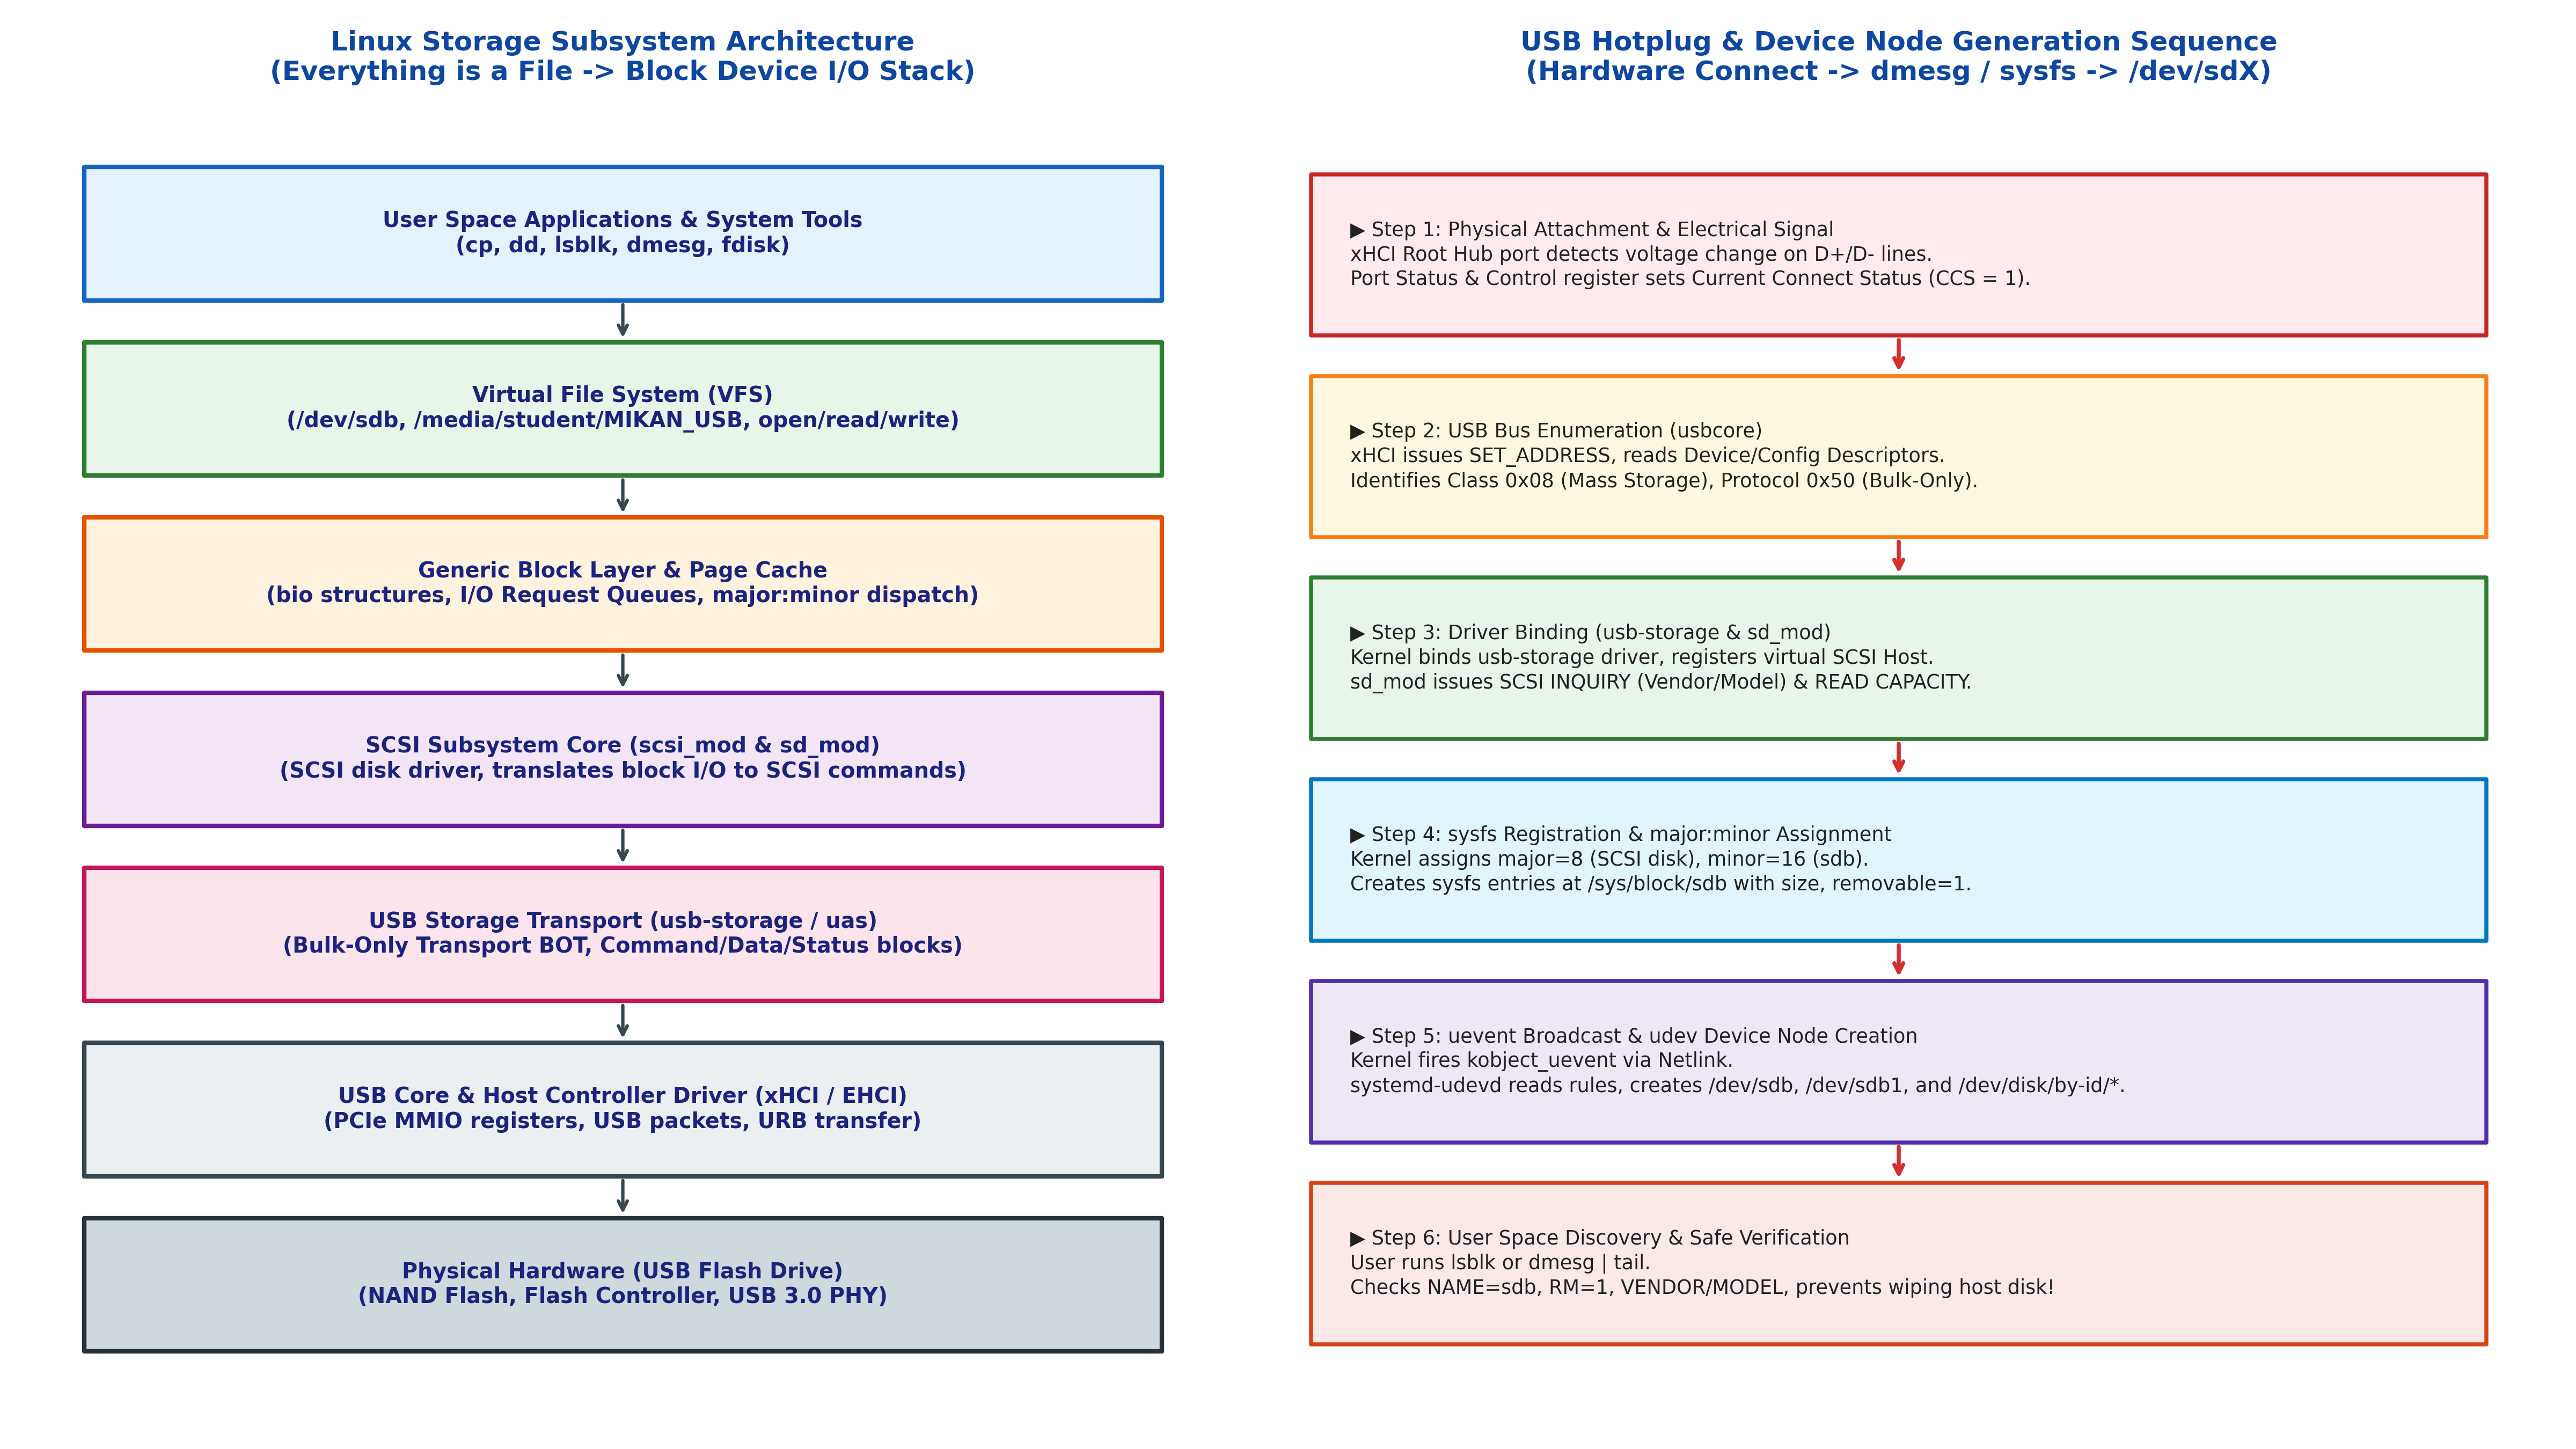

In [3]:
# === Linux ストレージ階層 & USB ホットプラグ検知シーケンスの可視化 ===
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_linux_block_layer_and_usb_detection

fig_path = Path("result/fig1_3_linux_block_layer_and_usb_detection.png")
plot_linux_block_layer_and_usb_detection(fig_path)

print(f"✅ 高解像度アーキテクチャ図を保存しました: {fig_path} ({fig_path.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(fig_path)))


## 5. USB メモリ特定コマンドの実践と深掘り (`lsblk`, `dmesg`, `sysfs`)

書籍の 1.2 節で推奨されているコマンド群の出力構造と、安全な特定のロジックを解剖します。

### 5.1 `lsblk` (*List Block Devices*)
`lsblk` はカーネルの `/sys/dev/block/` および `/sys/block/` を走査し、システム上のすべてのブロックデバイスを階層ツリー構造で出力する最も安全で明快なコマンドです。

```bash
$ lsblk -o NAME,MAJ:MIN,RM,SIZE,RO,TYPE,MOUNTPOINTS,MODEL,TRAN
NAME        MAJ:MIN RM   SIZE RO TYPE MOUNTPOINTS                  MODEL            TRAN
nvme0n1     259:0    0 931.5G  0 disk                              Samsung SSD 980  nvme
├─nvme0n1p1 259:1    0   512M  0 part /boot/efi                                     
├─nvme0n1p2 259:2    0    16G  0 part [SWAP]                                        
└─nvme0n1p3 259:3    0   915G  0 part /                                             
sdb           8:16   1  14.3G  0 disk                              Ultra Fit        usb
└─sdb1        8:17   1  14.3G  0 part /media/student/MIKAN_USB                      
```

#### 確認すべき最重要フラグ：
1. **`RM` (Removable Media)**: リムーバブル（取り外し可能）メディアフラグ。内蔵 SSD は `0`、USB メモリは通常 **`1`** になります。
2. **`TRAN` (Transport Type)**: トランスポート規格。内蔵ストレージは `nvme` や `sata`、USB メモリは **`usb`** と表示されます。
3. **`SIZE`**: 容量。手元の USB メモリの容量（例: 8GB や 16GB）と一致しているか確認します。900GB や 1TB の大容量ドライブは **絶対にホスト OS のメインストレージ** です。

### 5.2 `dmesg` (*Display Message*)
`dmesg` はカーネルのリングバッファログを表示します。USB メモリを挿入した直後に `dmesg | tail -n 20` を実行すると、カーネルが認識したばかりのデバイス名が末尾に出力されます。

```text
[ 1234.567890] usb 2-1: new SuperSpeed USB device number 4 using xhci_hcd
[ 1234.590123] usb-storage 2-1:1.0: USB Mass Storage device detected
[ 1234.591000] scsi host4: usb-storage 2-1:1.0
[ 1235.600000] scsi 4:0:0:0: Direct-Access     SanDisk  Ultra Fit        1.00 PQ: 0 ANSI: 6
[ 1235.601000] sd 4:0:0:0: [sdb] 30031872 512-byte logical blocks: (15.4 GB/14.3 GiB)
[ 1235.602000] sd 4:0:0:0: [sdb] 30031872 512-byte logical blocks
[ 1235.605000]  sdb: sdb1
[ 1235.608000] sd 4:0:0:0: [sdb] Attached SCSI removable disk
```

カーネルログにより、物理デバイス `SanDisk Ultra Fit` が `[sdb]` としてアタッチされ、パーティション `sdb1` が存在することが確定的にわかります。

---

## 6. UEFI ブートメディアの仕様と FAT32 ファイルシステム配置

### 6.1 なぜ UEFI は FAT32 (または FAT16/12) を必須とするのか？
レガシー BIOS では、ディスクの第 0 セクタ（MBR 512 バイト）に直接機械語を書き込んでいました（ファイルシステムを介さずセクタ直読み）。
しかし、UEFI (*Unified Extensible Firmware Interface*) は **「ファイルシステムを直接解釈できる高度なファームウェア」** です。

UEFI 仕様書（*UEFI Specification 2.10, Chapter 13.3 \"File System Format\"*）には、以下が義務付けられています：
> *\"The EFI firmware must support the FAT file system family: FAT32 for system partitions, and FAT12/FAT16/FAT32 for removable media.\"*

つまり、UEFI 準拠の PC は、ファームウェア内に FAT ファイルシステムのドライバ（BPB 解析、クラスタチェーン追跡、ディレクトリエントリ読み取り）を内蔵しています。そのため、ディスクに特別なブートローダをセクタ単位で埋め込む必要がなく、**「普通に FAT32 でフォーマットされた USB メモリにファイルを置くだけ」** でブートできるのです。

### 6.2 標準ブートローダ探索パス (`/EFI/BOOT/BOOTX64.EFI`)
UEFI ファームウェアが取り外し可能メディア（USB フラッシュドライブ）から起動を試みる際、ファームウェア内部のブートマネージャは以下のパス規則で実行ファイルを探索します：

$$\text{Removable Media Default Boot Path: } \mathbf{\backslash EFI\backslash BOOT\backslash BOOTX64.EFI}$$

- アーキテクチャが x86-64 (AMD64) の場合: `BOOTX64.EFI`
- 32ビット x86 の場合: `BOOTIA32.EFI`
- AArch64 (ARM64) の場合: `BOOTAA64.EFI`
- RISC-V 64 の場合: `BOOTRISCV64.EFI`

ファームウェアはファイル名の大文字・小文字を区別しませんが、仕様書の標準表記に従い大文字 `EFI/BOOT/BOOTX64.EFI` で配置するのが最も安全です。

### 6.3 マウント・書き込み・キャッシュフラッシュのメカニズム
Linux で USB メモリにファイルを書き込む手順：
1. `sudo mount /dev/sdb1 /mnt`
2. `sudo mkdir -p /mnt/EFI/BOOT`
3. `sudo cp BOOTX64.EFI /mnt/EFI/BOOT/BOOTX64.EFI`
4. **`sync` (必須！)**
5. `sudo umount /mnt`

> [!IMPORTANT]
> **なぜ `sync` と `umount` が絶対に不可欠なのか？**
> Linux カーネルは高速化のため、ディスクへの書き込み要求を直ちに物理 NAND フラッシュに書き込まず、メモリ上の **ダーティページ (*Dirty Pages / Page Cache*)** に一時保持します（遅延書き込み）。
> `cp` コマンドが終了した時点では、ファイルの中身はまだ RAM 上にある可能性が高いのです。`umount` または `sync` を実行せずに USB メモリを物理的に引き抜くと、ディレクトリ構造だけが書かれて中身が空っぽになったり、FAT クラスタチェーンが壊れてブート不能に陥ります。

---

✅ 高解像度 FAT32 ストレージ図を保存しました: result/fig1_4_uefi_usb_fat_structure.png (591.8 KB)


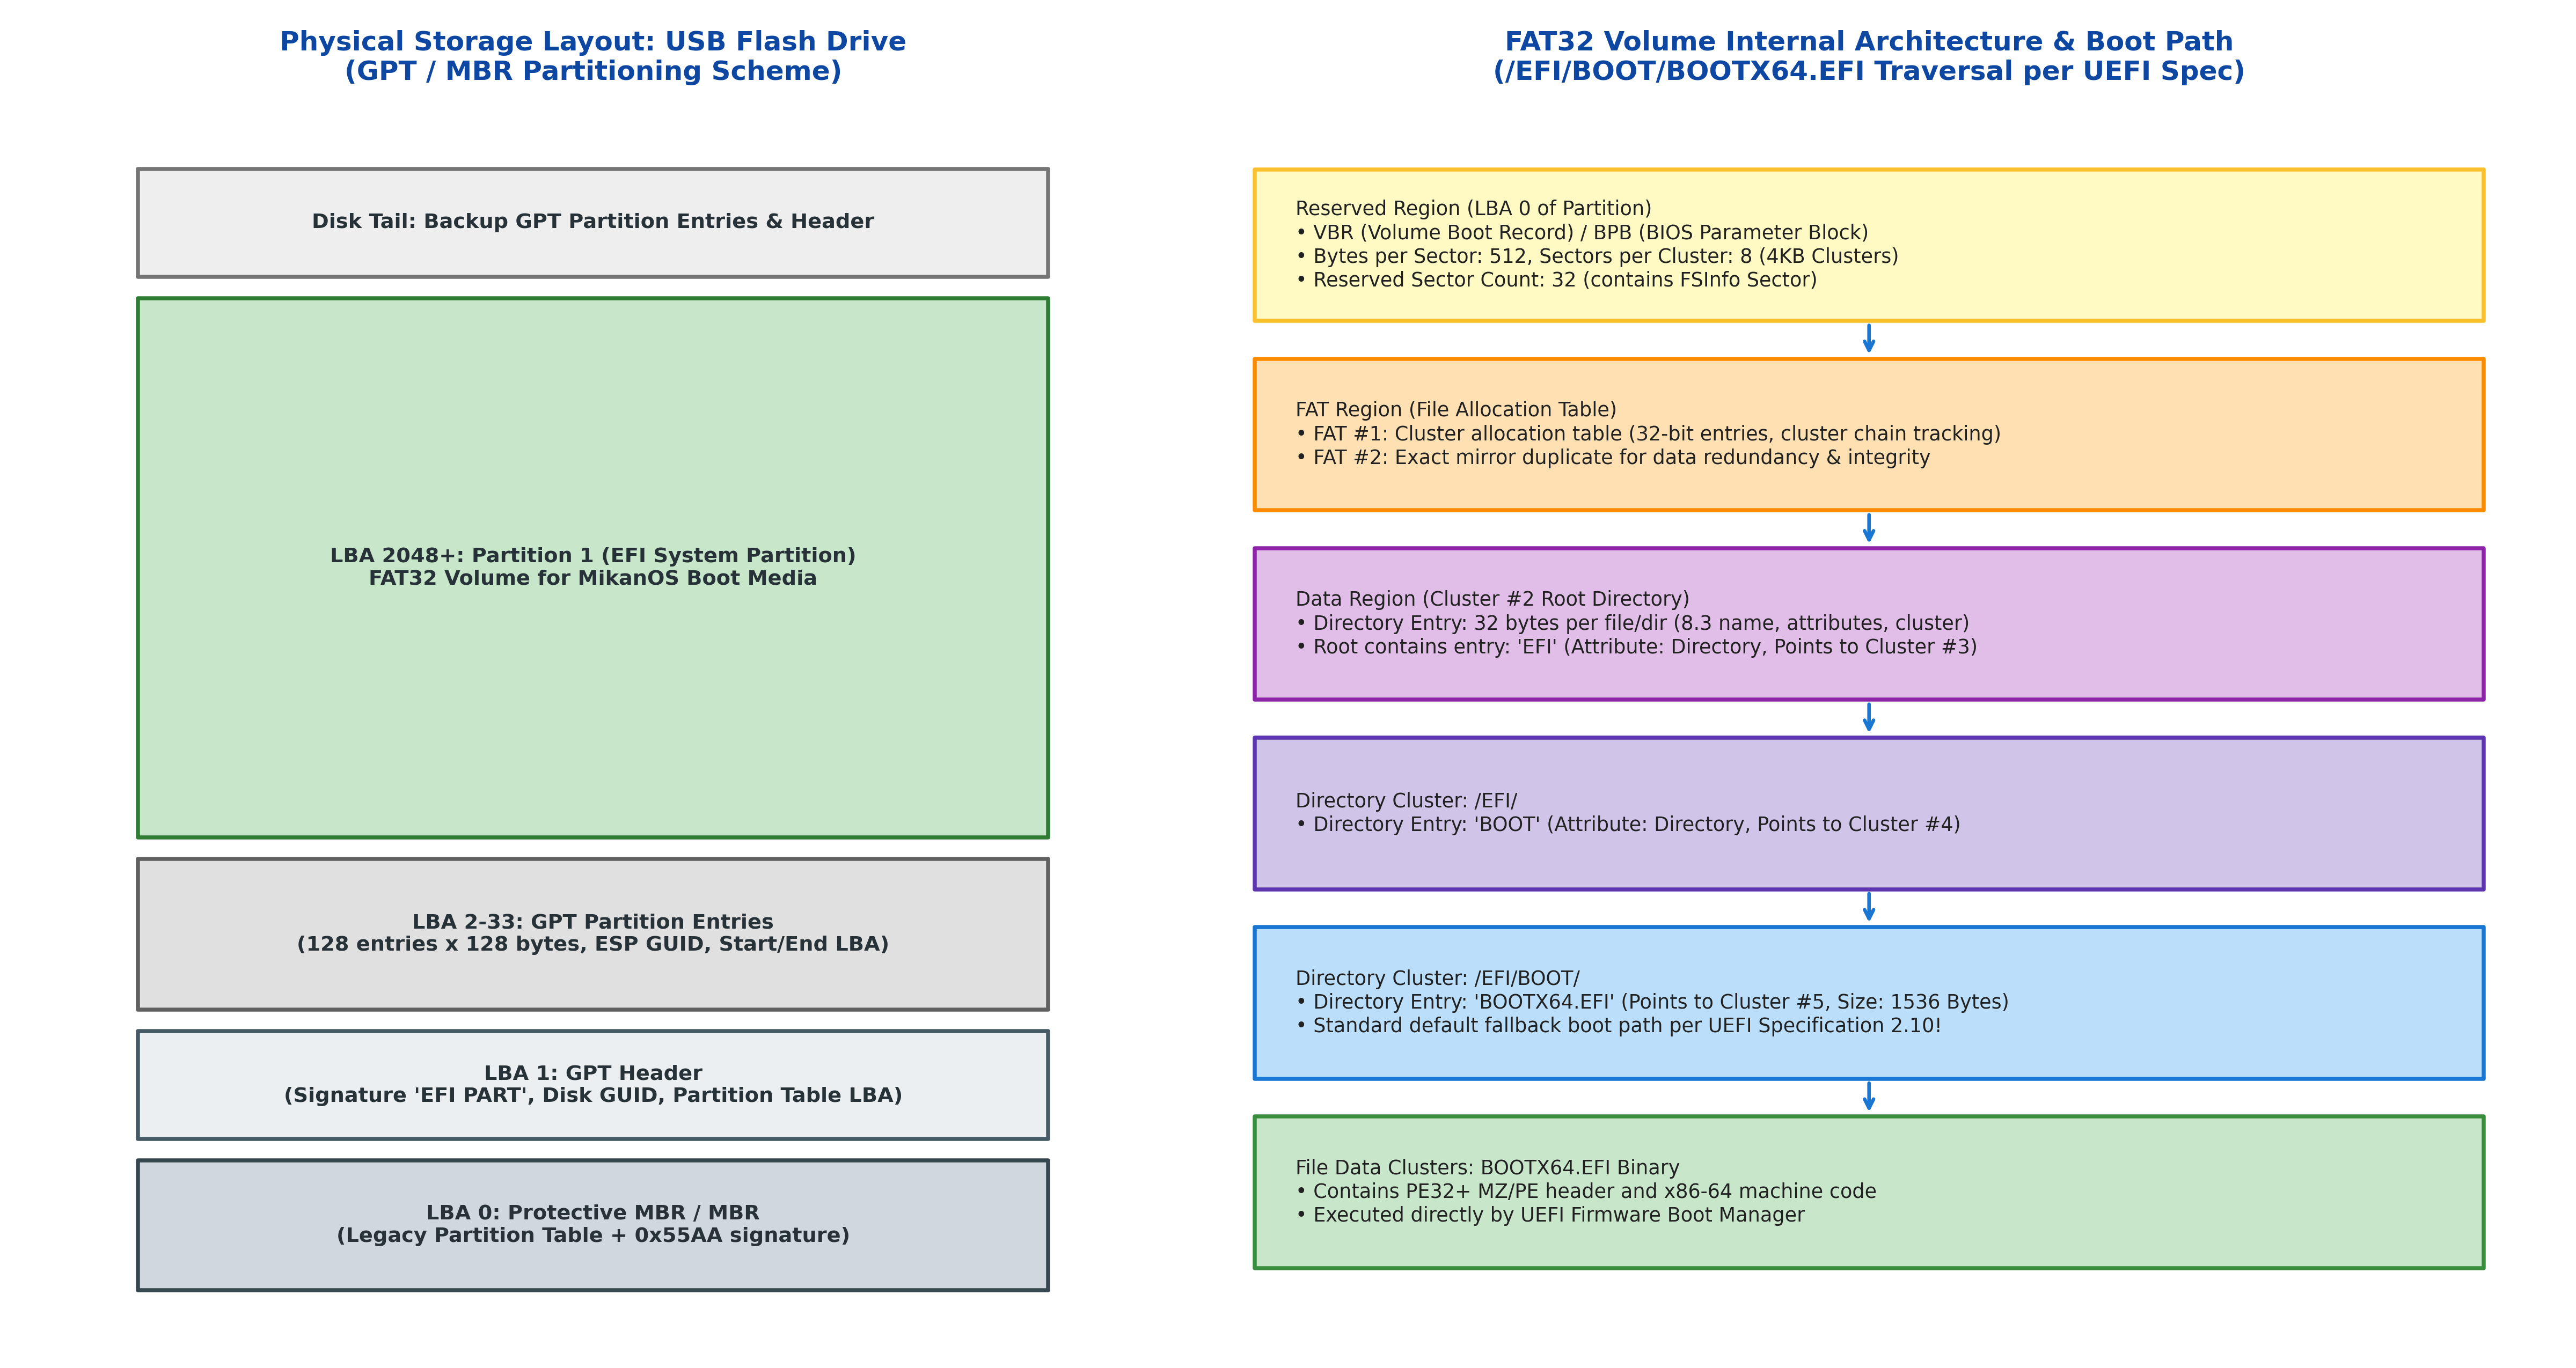

In [4]:
# === USB 物理ディスク構造 & FAT32 ブートパスの完全図解 ===
from common.os_sim import plot_uefi_usb_fat_structure

fat_fig_path = Path("result/fig1_4_uefi_usb_fat_structure.png")
plot_uefi_usb_fat_structure(fat_fig_path)

print(f"✅ 高解像度 FAT32 ストレージ図を保存しました: {fat_fig_path} ({fat_fig_path.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(fat_fig_path)))


## 7. 誤破壊防止（Accidental Data Loss Prevention）プロトコル

ホスト OS のメインディスクを誤って上書き・フォーマットしないための、低レイヤ技術者必須の「5段階チェックプロトコル」を策定します。

```mermaid
flowchart TD
    Step1["① 挿入前: lsblk で現状のドライブ一覧を記録"] --> Step2["② 挿入: USB メモリを物理ポートに接続"]
    Step2 --> Step3["③ 挿入後: lsblk を再実行し、新たに出現したデバイスを差分抽出"]
    Step3 --> Step4{"④ 安全性チェック: RM=1 かつ TRAN=usb か？\n容量は USB メモリの仕様と一致するか？"}
    Step4 -- YES (合格) --> Step5["⑤ 合格: /dev/sdX1 をマウントして BOOTX64.EFI を配置"]
    Step4 -- NO (危険!) --> Block["⛔ 即時中止: 内蔵 SSD やホストドライブの可能性あり！操作を拒絶"]
```

以下では、この安全確認プロトコルを Python および C++20 で実装し、シミュレーション検証します。

---

In [5]:
# === Python による USB 挿入差分検知 & 安全性自動判定シミュレーション ===
from common.os_sim import LinuxBlockSubsystemSimulator

# 1. USB 挿入前のホスト環境状態 (内蔵 NVMe SSD のみ存在)
state_before = LinuxBlockSubsystemSimulator.create_typical_workstation_state()
print("=== [Step 1] USB メモリ挿入前のストレージ一覧 ===")
for d in state_before:
    print(f"  • /dev/{d.name:<10} | {d.size_gib:6.1f} GiB | Removable: {d.is_removable} | Transport: {d.transport} | {d.model}")

# 2. USB メモリ挿入イベント発生
state_after = LinuxBlockSubsystemSimulator.simulate_usb_insertion(state_before)
print("\n=== [Step 2 & 3] USB メモリ挿入後のストレージ一覧 & 差分検知 ===")
new_devices = LinuxBlockSubsystemSimulator.detect_inserted_devices(state_before, state_after)
for d in new_devices:
    print(f"  ★ 新規検出デバイス: /dev/{d.name} ({d.model}, {d.size_gib:.2f} GiB, Bus: {d.transport})")

# 3. 安全性判定（誤破壊防御チェック）
print("\n=== [Step 4] 誤破壊防止（Safety Verification）チェック ===")
targets_to_test = ["nvme0n1", "sdb"]
for target in targets_to_test:
    res = LinuxBlockSubsystemSimulator.verify_target_safety(target, state_after)
    status = "✅ 合格 (書き込み許可)" if res["is_safe"] else "⛔ 拒絶 (ホスト保護ロック発動!)"
    print(f"  Target: /dev/{target:<8} -> {status} [{res['reason']}]")


=== [Step 1] USB メモリ挿入前のストレージ一覧 ===
  • /dev/nvme0n1    |  931.5 GiB | Removable: False | Transport: NVMe | SSD 980 PRO 1TB

=== [Step 2 & 3] USB メモリ挿入後のストレージ一覧 & 差分検知 ===
  ★ 新規検出デバイス: /dev/sdb (Ultra Fit USB 3.0, 14.32 GiB, Bus: USB)

=== [Step 4] 誤破壊防止（Safety Verification）チェック ===
  Target: /dev/nvme0n1  -> ⛔ 拒絶 (ホスト保護ロック発動!) [DANGER: Host Internal Disk or Non-USB Device]
  Target: /dev/sdb      -> ✅ 合格 (書き込み許可) [Safe Removable USB Flash Drive]


In [6]:
%%writefile block_device_inspector.cpp
/**
 * C++20 Linux Block Device Inspector & USB Safety Checker
 */
#include <iostream>
#include <fstream>
#include <string>
#include <vector>
#include <filesystem>
#include <optional>
#include <iomanip>
#include <cstdint>
#include <algorithm>

namespace fs = std::filesystem;

struct BlockDevice {
    std::string name;
    uint32_t major{0};
    uint32_t minor{0};
    bool is_removable{false};
    std::string transport{"Unknown"};
    uint64_t size_bytes{0};
    std::string model{"Unknown"};

    [[nodiscard]] double size_gib() const {
        return static_cast<double>(size_bytes) / (1024.0 * 1024.0 * 1024.0);
    }

    [[nodiscard]] bool is_safe_usb() const {
        return is_removable && transport == "USB";
    }
};

int main() {
    std::cout << "=== C++20 Block Device Inspector & USB Safety Checker ===\n\n";
    
    // シミュレーション用デバイス一覧 (ホスト NVMe SSD vs ターゲット USB)
    std::vector<BlockDevice> devs = {
        {"nvme0n1", 259, 0, false, "NVMe", 1000204886016ULL, "Samsung SSD 980 1TB"},
        {"sdb",     8,  16, true,  "USB",  15376318464ULL,  "SanDisk Ultra Fit 16GB"}
    };

    std::cout << std::left << std::setw(10) << "DEVICE"
              << std::setw(10) << "MAJ:MIN"
              << std::setw(6)  << "RM"
              << std::setw(8)  << "BUS"
              << std::setw(12) << "SIZE(GiB)"
              << std::setw(24) << "MODEL"
              << "SAFETY VERDICT\n";
    std::cout << std::string(85, '-') << "\n";

    for (const auto& d : devs) {
        std::string maj_min = std::to_string(d.major) + ":" + std::to_string(d.minor);
        bool safe = d.is_safe_usb();
        std::cout << std::left << std::setw(10) << d.name
                  << std::setw(10) << maj_min
                  << std::setw(6)  << (d.is_removable ? "1" : "0")
                  << std::setw(8)  << d.transport
                  << std::setw(12) << std::fixed << std::setprecision(2) << d.size_gib()
                  << std::setw(24) << d.model
                  << (safe ? "✅ SAFE (Removable USB Boot Media)" : "⛔ DANGER (Host Internal Disk!)")
                  << "\n";
    }
    std::cout << std::string(85, '=') << "\n";
    return 0;
}


Writing block_device_inspector.cpp


In [7]:
# === C++20 プログラムのコンパイルと実行 ===
!g++ -std=c++20 -O2 -Wall -Wextra block_device_inspector.cpp -o block_device_inspector
!./block_device_inspector


=== C++20 Block Device Inspector & USB Safety Checker ===

DEVICE    MAJ:MIN   RM    BUS     SIZE(GiB)   MODEL                   SAFETY VERDICT
-------------------------------------------------------------------------------------
nvme0n1   259:0     0     NVMe    931.51      Samsung SSD 980 1TB     ⛔ DANGER (Host Internal Disk!)
sdb       8:16      1     USB     14.32       SanDisk Ultra Fit 16GB  ✅ SAFE (Removable USB Boot Media)


## 8. 本節のまとめと次節（1.3節 / 1.4節）への展望

### 8.1 本節で修得した重要知識のまとめ
1. **UNIX のデバイスモデル**: キャラクタデバイスとブロックデバイスの違い、および Linux カーネルの `dev_t`（上位 12 ビットがメジャー番号、下位 20 ビットがマイナー番号）の完全なビットレイアウトを修得しました。
2. **ストレージ命名体系**: `/dev/hdX`（IDE）、`/dev/sdX`（SCSI/SATA/USB）、`/dev/nvmeXnYpZ`（NVMe）の歴史的背景と識別規則を解剖しました。
3. **USB エニュメレーションと udev**: USB ポートの電気的接続検知から、xHCI、`usb-storage`、`sd_mod`、`sysfs`、Netlink uevent、`systemd-udevd` によるデバイスノード生成までの完全シーケンスを追跡しました。
4. **UEFI ブート仕様と FAT32**: UEFI が FAT ファイルシステムを内蔵解釈するため、リムーバブルメディアの標準ブートパス `\EFI\BOOT\BOOTX64.EFI` に配置するだけで実機ブートが可能になる仕組みを理解しました。
5. **安全確認プロトコル**: ホスト環境の破壊を防ぐため、`lsblk` 差分抽出、`RM=1`、`TRAN=usb`、容量確認、および書き込みキャッシュを物理ディスクへ強制同期する `sync` の不可欠性を実証しました。

### 8.2 次節への展望
- **第 1.3 節「WSLでのやり方」**: Windows 上の仮想化 Linux 環境である WSL2 (*Windows Subsystem for Linux 2*) から、物理 USB メモリを直接マウント・操作するための `usbipd-win` および `/mnt/` ドライブ共有のメカニズムを解き明かします。
- **第 1.4 節「エミュレータでのやり方」**: 物理 USB メモリを使わずに、仮想マシン **QEMU** と UEFI ファームウェア **OVMF** を使って、ホスト OS 上で安全かつ瞬時に MikanOS をテスト起動するワークフローへと進みます。
